<a href="https://colab.research.google.com/github/angelvb2104-ops/online-retail-analysis/blob/main/Retail_Data_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
ur12 = "https://archive.ics.uci.edu/static/public/352/data.csv"
df = pd.read_csv(ur12)
print(df.shape)
print(df.head())

(541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  


In [2]:
# CLEANING - Use this same rule everywhere
print("Before:", df.shape)
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

df_clean = df.copy()
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.dropna(subset=['InvoiceNo','StockCode','Quantity','UnitPrice'])

# Valid Sale = Quantity > 0 AND UnitPrice > 0 AND InvoiceNo NOT starting with 'C'
df_valid = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]
df_valid = df_valid[~df_valid['InvoiceNo'].astype(str).str.startswith('C')]

df_valid['Revenue'] = df_valid['Quantity'] * df_valid['UnitPrice']
df_valid['InvoiceDate'] = pd.to_datetime(df_valid['InvoiceDate'])
df_valid['Year'] = df_valid['InvoiceDate'].dt.year
df_valid['Month'] = df_valid['InvoiceDate'].dt.month
df_valid['Hour'] = df_valid['InvoiceDate'].dt.hour

print("After cleaning:", df_valid.shape)
print("Total Revenue:", df_valid['Revenue'].sum())
print("Total Invoices:", df_valid['InvoiceNo'].nunique())

# Save for SQL later
df_valid.to_csv('Retail_Cleaned_Data.csv', index=False)
print("Saved!")

Before: (541909, 8)
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Duplicates: 5268
After cleaning: (524878, 12)
Total Revenue: 10642110.804000001
Total Invoices: 19960
Saved!


In [3]:
# B3 - PRODUCT ANALYSIS
top_products = df_valid.groupby(['StockCode','Description'])['Revenue'].sum().sort_values(ascending=False).head(10)
print("TOP 10 PRODUCTS BY REVENUE")
print(top_products)
print("\n")

# B4 - CUSTOMER & COUNTRY
df_customer = df_valid.dropna(subset=['CustomerID'])
top_customers = df_customer.groupby('CustomerID')['Revenue'].sum().sort_values(ascending=False).head(10)
print("TOP 10 CUSTOMERS")
print(top_customers)
print("\n")

country = df_valid.groupby('Country')['Revenue'].sum().sort_values(ascending=False)
print("REVENUE BY COUNTRY")
print(country.head(10))
print("\n")

# B5 - TIME ANALYSIS
monthly = df_valid.groupby(['Year','Month'])['Revenue'].sum()
print("MONTHLY REVENUE")
print(monthly)
print("\n")

hourly = df_valid.groupby('Hour')['Revenue'].sum()
print("HOURLY REVENUE")
print(hourly)

TOP 10 PRODUCTS BY REVENUE
StockCode  Description                       
DOT        DOTCOM POSTAGE                        206248.77
22423      REGENCY CAKESTAND 3 TIER              174156.54
23843      PAPER CRAFT , LITTLE BIRDIE           168469.60
85123A     WHITE HANGING HEART T-LIGHT HOLDER    104284.24
47566      PARTY BUNTING                          99445.23
85099B     JUMBO BAG RED RETROSPOT                94159.81
23166      MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POST       POSTAGE                                78101.88
M          Manual                                 77750.27
23084      RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64


TOP 10 CUSTOMERS
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64


REVENUE BY COUNTRY
Country
United K

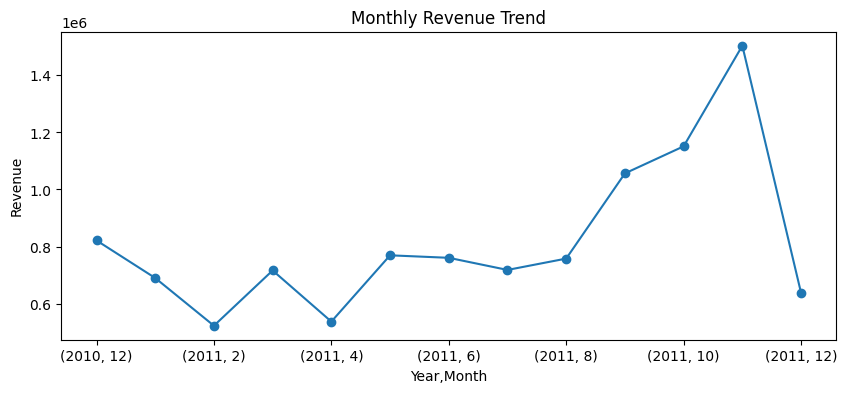

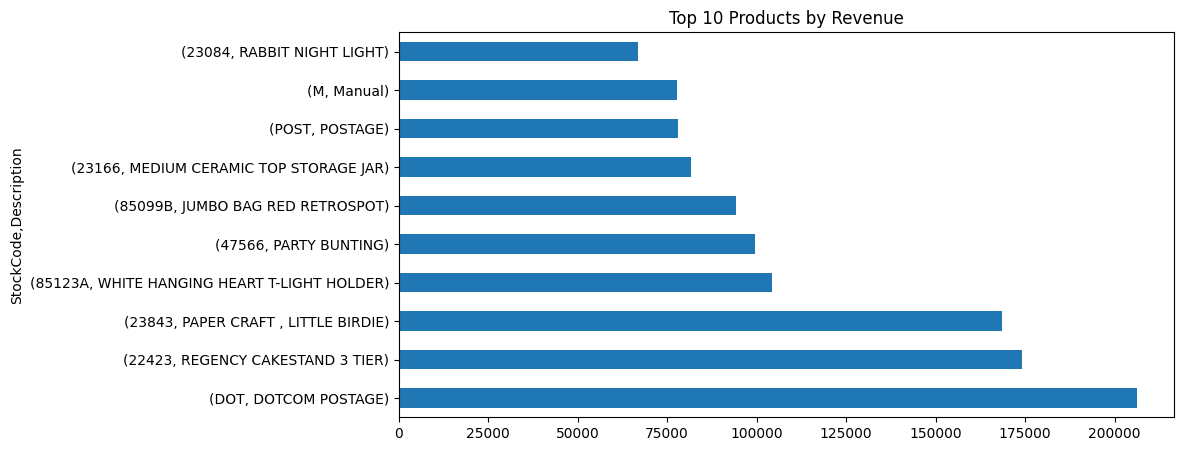

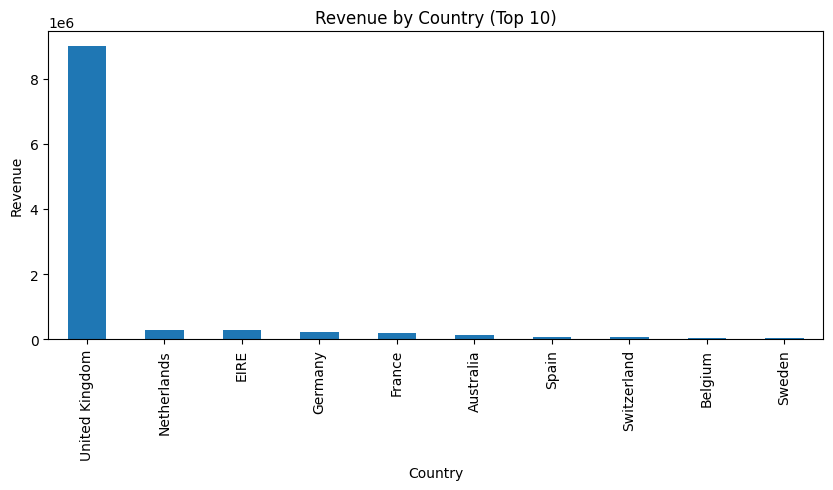

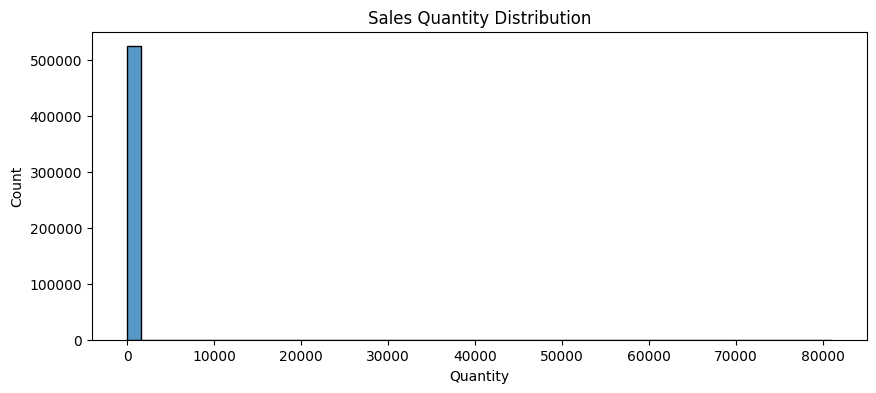

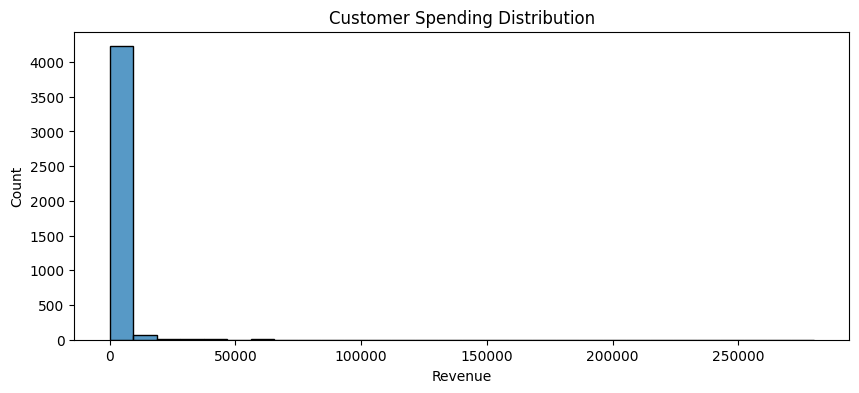

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Monthly Trend
monthly_plot = df_valid.groupby(['Year','Month'])['Revenue'].sum()
monthly_plot.plot(kind='line', marker='o', figsize=(10,4))
plt.title('Monthly Revenue Trend')
plt.ylabel('Revenue')
plt.show()

# 2. Top 10 Products
top_products.head(10).plot(kind='barh', figsize=(10,5))
plt.title('Top 10 Products by Revenue')
plt.show()

# 3. Revenue by Country Top 10
country.head(10).plot(kind='bar', figsize=(10,4))
plt.title('Revenue by Country (Top 10)')
plt.ylabel('Revenue')
plt.show()

# 4. Quantity Distribution
plt.figure(figsize=(10,4))
sns.histplot(df_valid['Quantity'], bins=50)
plt.title('Sales Quantity Distribution')
plt.show()

# 5. Customer Spending Distribution
plt.figure(figsize=(10,4))
sns.histplot(df_customer.groupby('CustomerID')['Revenue'].sum(), bins=30)
plt.title('Customer Spending Distribution')
plt.show()

In [6]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('retail.db')
df_valid.to_sql('sales', conn, if_exists='replace', index=False)
print("Data loaded to SQL!")

print("\n--- SQL 1: Total Revenue ---")
print(pd.read_sql("SELECT SUM(Revenue) as Total_Revenue FROM sales", conn))

print("\n--- SQL 2: Top 10 Products ---")
print(pd.read_sql("SELECT Description, SUM(Revenue) as Revenue FROM sales GROUP BY Description ORDER BY Revenue DESC LIMIT 5", conn))

print("\n--- SQL 3: Country Revenue ---")
print(pd.read_sql("SELECT Country, SUM(Revenue) as Revenue FROM sales GROUP BY Country ORDER BY Revenue DESC LIMIT 5", conn))

print("\n--- SQL 4: Monthly Trend ---")
print(pd.read_sql("SELECT Year, Month, SUM(Revenue) as Revenue FROM sales GROUP BY Year, Month ORDER BY Revenue DESC LIMIT 5", conn))

print("\n--- SQL 5: Top Customer ---")
print(pd.read_sql("SELECT CustomerID, SUM(Revenue) as Revenue FROM sales WHERE CustomerID IS NOT NULL GROUP BY CustomerID ORDER BY Revenue DESC LIMIT 5", conn))

Data loaded to SQL!

--- SQL 1: Total Revenue ---
   Total_Revenue
0   1.064211e+07

--- SQL 2: Top 10 Products ---
                          Description    Revenue
0                      DOTCOM POSTAGE  206248.77
1            REGENCY CAKESTAND 3 TIER  174156.54
2         PAPER CRAFT , LITTLE BIRDIE  168469.60
3  WHITE HANGING HEART T-LIGHT HOLDER  106236.72
4                       PARTY BUNTING   99445.23

--- SQL 3: Country Revenue ---
          Country      Revenue
0  United Kingdom  9001744.094
1     Netherlands   285446.340
2            EIRE   283140.520
3         Germany   228678.400
4          France   209625.370

--- SQL 4: Monthly Trend ---
   Year  Month      Revenue
0  2011     11  1503866.780
1  2011     10  1151263.730
2  2011      9  1056435.192
3  2010     12   821452.730
4  2011      5   769296.610

--- SQL 5: Top Customer ---
   CustomerID    Revenue
0     14646.0  280206.02
1     18102.0  259657.30
2     17450.0  194390.79
3     16446.0  168472.50
4     14911.0  14371